In [125]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.api.types import is_string_dtype,is_int64_dtype,is_float_dtype
import yaml

In [126]:
with open("../configure.yaml", "r") as f:
    config = yaml.safe_load(f)
    
target=config["target"]

In [127]:
dataframe=[]
for rutas in range(0,4):
    ruta=(f"../data/bronze/train{rutas}.parquet")
    parque=pd.read_parquet(ruta)
    dataframe.append((parque))
    df=pd.concat(dataframe,ignore_index=False)
df

,id,date,store_nbr,family,sales,onpromotion
0,1039680,2014-08-08,30,HOME AND KITCHEN I,0.0,0
1,1039681,2014-08-08,30,HOME AND KITCHEN II,0.0,0
2,1039682,2014-08-08,30,HOME APPLIANCES,0.0,0
3,1039683,2014-08-08,30,HOME CARE,0.0,0
4,1039684,2014-08-08,30,LADIESWEAR,0.0,0
...,...,...,...,...,...,...
883,1039675,2014-08-08,30,EGGS,70.0,0
884,1039676,2014-08-08,30,FROZEN FOODS,21.0,0
885,1039677,2014-08-08,30,GROCERY I,944.0,0
886,1039678,2014-08-08,30,GROCERY II,5.0,0


In [128]:
df.shape

(3000888, 6)

In [129]:
df.info()

<class 'pandas.DataFrame'>
Index: 3000888 entries, 0 to 887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         str    
 2   store_nbr    int64  
 3   family       str    
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 160.3 MB


### MEMORIA

In [130]:
def memoria(df):
    df["date"]=pd.to_datetime(df["date"])
    for col in df.columns:
        if is_string_dtype(df[col]):
            df[col]=df[col].astype("category")

        elif is_float_dtype(df[col]):
            df[col]=pd.to_numeric(df[col],downcast="float")

        elif is_integer_dtype(df[col]):
            df[col]=pd.to_numeric(df[col],downcast="integer")
    
    return df

df=memoria(df)
df.info()

<class 'pandas.DataFrame'>
Index: 3000888 entries, 0 to 887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int32         
 1   date         datetime64[us]
 2   store_nbr    int8          
 3   family       category      
 4   sales        float64       
 5   onpromotion  int16         
dtypes: category(1), datetime64[us](1), float64(1), int16(1), int32(1), int8(1)
memory usage: 91.6 MB


In [131]:
df.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [132]:
df.duplicated().sum()

np.int64(0)

### CORRELACION

<Axes: >

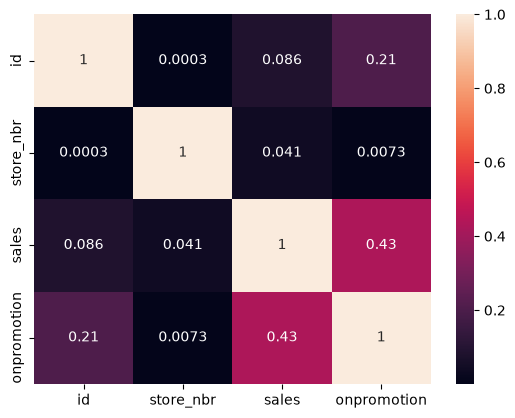

In [133]:
col_number=df.select_dtypes(include="number").columns
col_category=df.select_dtypes(include="category").columns

sns.heatmap(df[col_number].corr(),annot=True)

In [134]:
df.select_dtypes(include="number").corr()[target].sort_values(ascending=False)

sales          1.000000
onpromotion    0.427923
id             0.085784
store_nbr      0.041196
Name: sales, dtype: float64

In [135]:
def inportancia():
    resultado=[]
    for col in col_category:
        top=df.groupby(col)[target].mean()
        diff=top.max()-top.min()
        resultado.append((col,diff))
    res=pd.DataFrame(resultado,columns=["category","diff"])
    res.sort_values(by="diff",ascending=False)
    return res

inportancia()

,category,diff
0,family,3776.901303


### OUTLIERS

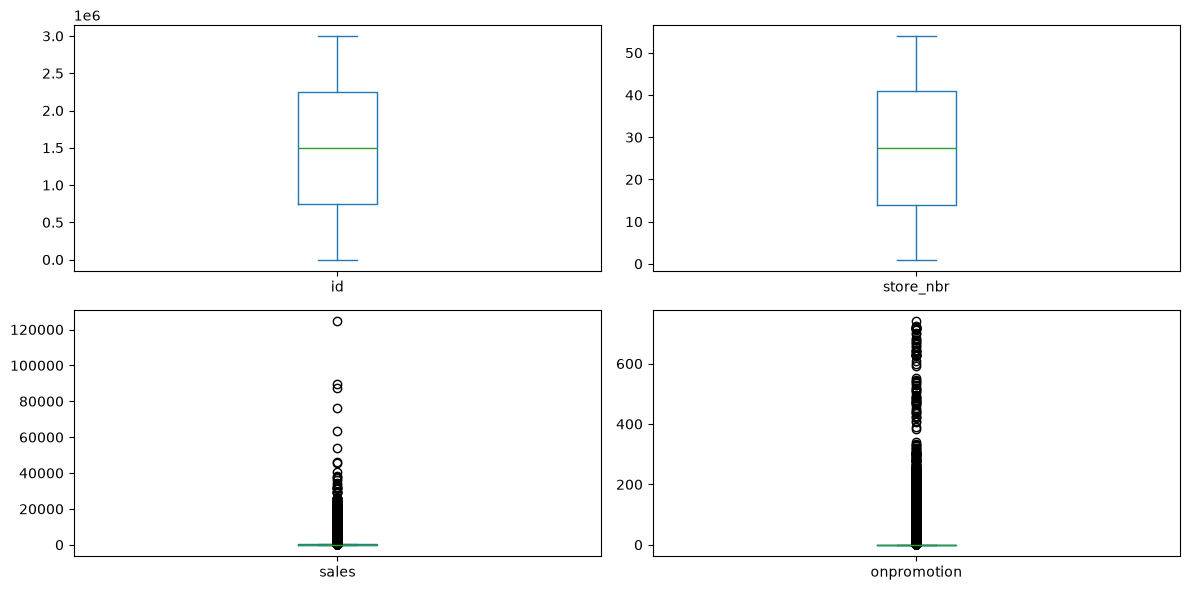

In [136]:
df.plot(kind="box",subplots=True,layout=(2,2),figsize=(12,6),sharex=False,sharey=False)
plt.tight_layout()
plt.show()

## EDA PROFUNDO